In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch

# ── 1. Load data ──────────────────────────────────────────────────────────────
cesm2_past   = xr.open_dataset(
    '/home/jwille/xenon_data/NextGEMS/dry_spells/'
    'CESM2_ens_1850-2014_dry_spell_summer_30-60N.nc'
)['__xarray_dataarray_variable__']

cesm2_future = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/CESM2_ens_2015-2049_dry_spell_summer_30-60N.nc')['__xarray_dataarray_variable__']

# Land-sea mask: shape (1, lat, lon) → squeeze to (lat, lon)
land_sea_cesm2 = xr.open_dataset(
    '/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc'
)['MASK'][0, :, :]

# ── 2. Concatenate and apply land mask ────────────────────────────────────────
cesm2_all  = xr.concat([cesm2_past, cesm2_future], dim='year')

latitude = [30,60]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2_all.lat, lon=cesm2_all.lon)
cesm2_all = cesm2_all.where(land_sea_cesm2 > 0, np.nan)


cesm2_land = cesm2_all.where(land_sea_cesm2 > 0, np.nan)

# ── 3. Select the same periods as the IFS version ────────────────────────────
# Adjust isel indices to match whichever 15-year windows you want.
# The box plot in the original notebook used 2021–2035 and 2035–2049;
# match those here by selecting from the concatenated year axis.
# Average over members first, then split periods
cesm2_land_ensmean = cesm2_land.mean(dim='member')



early = cesm2_land_ensmean.isel(year=slice(171, 185))
late  = cesm2_land_ensmean.isel(year=slice(185, 200))

# ── 4. Build cosine-latitude area weights (lat, lon) → broadcast to full dims ─
lat_rad     = np.deg2rad(cesm2_land.lat.values)
cos_lat_2d  = np.cos(lat_rad)[:, np.newaxis] * np.ones(len(cesm2_land.lon))  # (lat, lon)
cos_lat_2d  = np.where(land_sea_cesm2.values > 0, cos_lat_2d, np.nan)        # land only

# ── 1. Concatenate and split periods (no land mask yet) ───────────────────────
cesm2_all = xr.concat([cesm2_past, cesm2_future], dim='year')
early_all = cesm2_all.isel(year=slice(171, 185))   # (member, 15, lat, lon)
late_all  = cesm2_all.isel(year=slice(185, 200))   # (member, 15, lat, lon)

# ── 2. Compute area fractions per member ──────────────────────────────────────
bin_edges  = [0, 10, 20, 30, 50, np.inf]
bin_labels = ['0–10', '10–20', '20–30', '30–50', '50+']

def area_fractions_2d_masked(da):
    """
    da has dims (year, lat, lon), with ocean already NaN.
    Returns array of shape (n_years, n_bins) with cos-lat weighted area fractions.
    """
    fracs_per_year = []
    for yr in da.year.values:
        yr_data = da.sel(year=yr).values
        vals = yr_data.ravel()
        wts  = cos_lat_2d.ravel()
        valid = ~np.isnan(vals) & ~np.isnan(wts)
        vals, wts = vals[valid], wts[valid]
        total_w = wts.sum()
        if total_w == 0:
            fracs_per_year.append([np.nan] * len(bin_labels))
            continue
        fracs = []
        for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
            mask = (vals >= lo) & (vals < hi)
            fracs.append(100.0 * wts[mask].sum() / total_w)
        fracs_per_year.append(fracs)
    return np.array(fracs_per_year)   # (n_years, n_bins)

n_members  = cesm2_all.sizes['member']
pct_change_per_member = []

for m in range(n_members):
    # slice single member and apply land mask
    early_m = early_all.isel(member=m).where(land_sea_cesm2 > 0, np.nan)
    late_m  = late_all.isel(member=m).where(land_sea_cesm2 > 0, np.nan)

    ef = area_fractions_2d_masked(early_m)
    lf = area_fractions_2d_masked(late_m)

    em = np.nanmean(ef, axis=0)   # (n_bins,)
    lm = np.nanmean(lf, axis=0)   # (n_bins,)

    #pct_change_per_member.append(100.0 * (lm - em) / em)
    pct_change_per_member.append(lm - em)
pct_change_per_member = np.array(pct_change_per_member)   # (n_members, n_bins)


-0.7616615612350351
hi
-0.6207782848471828
-0.4246044193877886
hi
-0.6681002304258321
0.44698970994148934
hi
0.2660591203410867
-0.04420370549810641
hi
0.006399495621067786
0.7834799761794397
hi
0.9941173335443523


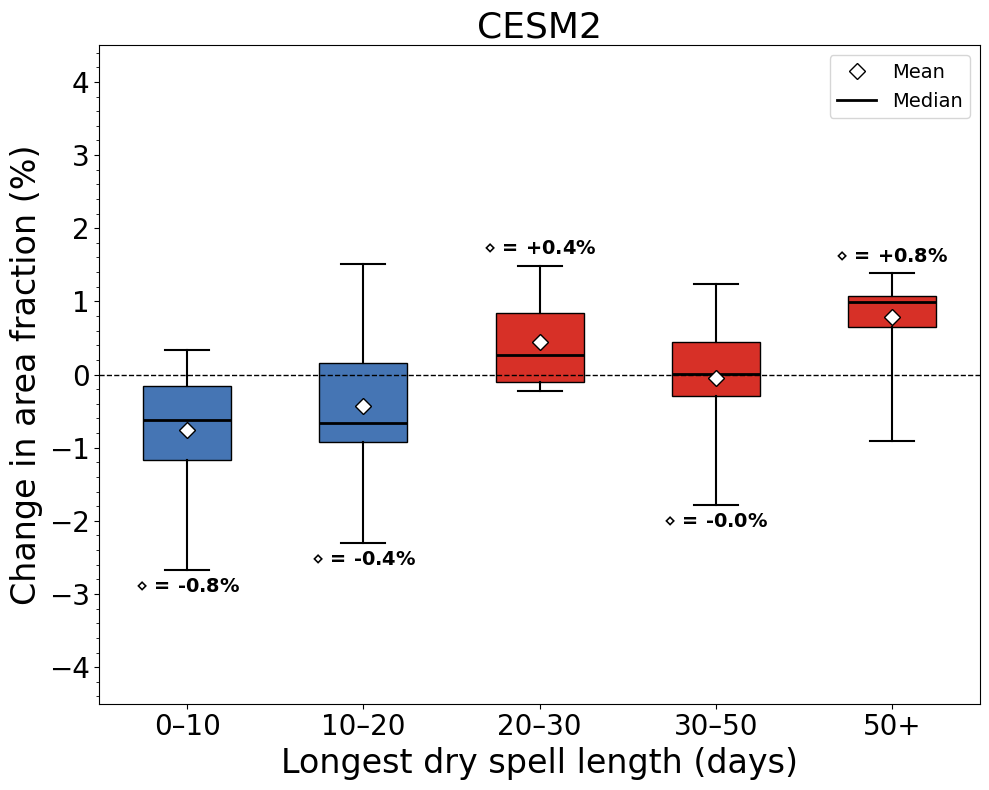

In [7]:
# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
x = np.arange(len(bin_labels))

data_by_bin = [pct_change_per_member[:, i] for i in range(len(bin_labels))]

bp = ax.boxplot(
    data_by_bin,
    positions=x,
    widths=0.5,
    whis=(0, 100),            # whiskers extend to min/max
    patch_artist=True,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
)

# Colour each box based on whether the median is positive or negative
for patch, data in zip(bp['boxes'], data_by_bin):
    median = np.median(data)
    patch.set_facecolor('#d73027' if median >= 0 else '#4575b4')

# Annotate with mean value just beyond the end of each whisker
# Annotate with mean value along the bottom of the plot
for i, data in enumerate(data_by_bin):
    mean_val = np.mean(data)

    if mean_val >= 0:
        ypos = np.max(data) + 0.1
        va   = 'bottom'
    else:
        ypos = np.min(data) - 0.1
        va   = 'top'
    ax.text(
        i,
        ypos,
        f'$\\diamond$ = {mean_val:+.1f}%',
        ha='center',
        va=va,
        fontsize=14, fontweight='bold'
    )

ax.axhline(0, color='black', linewidth=1.0, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels(bin_labels, fontsize=20)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Change in area fraction (%)', fontsize=24)
ax.tick_params(axis='both', labelsize=20)
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.set_ylim(-4.5, 4.5)
ax.set_title('CESM2', fontsize=26)

from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='D', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=8, label='Mean'),
    Line2D([0], [0], color='black', linewidth=2, label='Median'),
]
ax.legend(handles=legend_elements, fontsize=14, loc='upper right')


plt.tight_layout()
plt.savefig(
    '/home/jwille/images/global_paper/mid_lat_land_cesm2_ens_barplot_dry_spell_change.pdf',
    format='pdf', bbox_inches='tight'
)
plt.show()